In [1]:
import numpy as np
from numpy.polynomial import chebyshev as cheb
from scipy import optimize
import matplotlib.pyplot as plt
from tqdm import tqdm

# Force Modell

In [2]:
Lp = 1.5 # um Persistence length
kbT = 1

In [3]:
def x_entropic_force(Fe):
    return 1 / np.tanh(2 * Lp * Fe / kbT) - kbT / (2 * Lp * Fe)

def dx_entropic_force(Fe):
    return 1 / (2 * Lp * Fe**2 / kbT) - 2 * Lp / kbT / np.sinh(2 * Lp * Fe / kbT)**2

In [44]:
def create_F(k, sample_density_x=1e-3, n_iter_equalize=5, x_max_full=5, cheb_subsampling = 16, interpolation_gap = 0):
    
    ''' Creates a force curve for a given w.
        We return a chebychev polynomial that
        approximates the entire curve.

        From the experimental force rate w:
        k = w / v
    '''

    # Find F*, the transition from entropic to hookean force.
    res = optimize.root_scalar(lambda fe: dx_entropic_force(fe) - 1/k, bracket=(1e-12, 30))
    F_star = res.root

    # Determine the x range for forces to occur between 0 and F*
    x_min = x_entropic_force(sample_density_x)
    x_max = x_entropic_force(F_star)

    # Construct an even x grid of forces using the derivative of x
    n_x = max(int((x_max - x_min) / sample_density_x), 2)
    F  = np.linspace(1e-12, F_star, n_x)
    for _ in range(n_iter_equalize):
        cdx = np.cumsum(1/dx_entropic_force(F))
        cdx = cdx - cdx[0]
        cdx = cdx / cdx[-1]
        F = cdx * (F_star) + sample_density_x
    x = x_entropic_force(F)

    # The Hookean tail
    hook_tail_length = x_max_full - x_max
    xh = np.linspace(sample_density_x, hook_tail_length, int((hook_tail_length - sample_density_x) / sample_density_x))
    Fh = k * xh + F[-1]

    cutoff = interpolation_gap//2

    x = np.concatenate(([0], x[:-cutoff if cutoff else None], (xh + x[-1])[cutoff:]))
    F = np.concatenate(([0], F[:-cutoff if cutoff else None], Fh[cutoff:]))

    C = cheb.Chebyshev.fit(x, F, len(x)//cheb_subsampling)
    
    return C, x, F

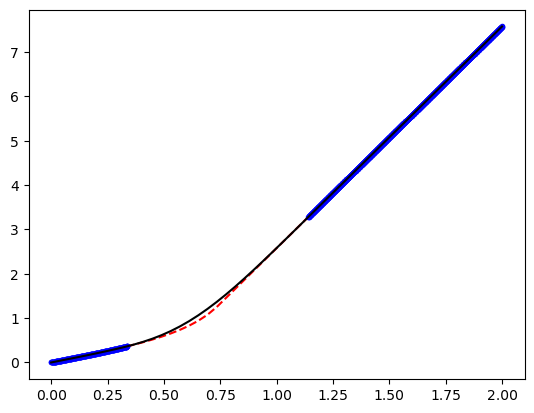

In [51]:
k = 5
C, x, F = create_F(k)
#plt.plot(x, F, ',b')
x = np.linspace(0, 2)
plt.plot(x, C(x), '--r')

C, x, F = create_F(k, interpolation_gap=800, x_max_full=2, cheb_subsampling=100)
plt.plot(x, F, '.b')
x = np.linspace(0, 2)
plt.plot(x, C(x), 'k')

# Simulate Trajectories

In [6]:
def sim(C, ru0, xu, v=0.2, dt=1e-2):
    t = 0
    ft = [C(t*v)]
    while True:
        assert v*t < 2
        pu = np.clip(dt * ru0 * np.exp(C(v*t)*xu), 0, 1)
        if pu > np.random.rand(1):
            break
        ft.append(C(v*t))
        t += dt

    return np.array(ft)

Text(0, 0.5, 'F')

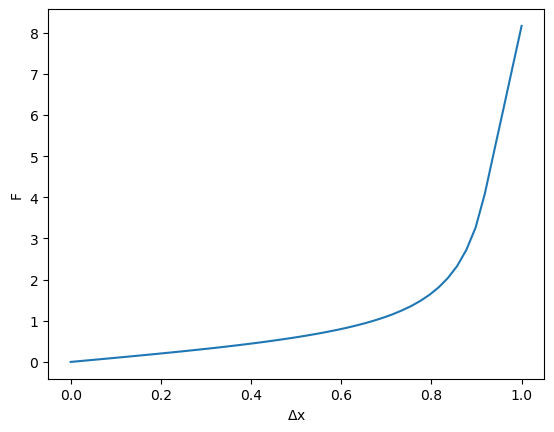

In [7]:
C, x, F = create_F(50)
x = np.linspace(0, 1)
F = C(x)
plt.plot(x,F)
plt.xlabel("$\Delta$x")
plt.ylabel("F")

# Simulate Trajectories

100%|███████████████████████████████████████| 2500/2500 [02:01<00:00, 20.54it/s]


2500 Measurements


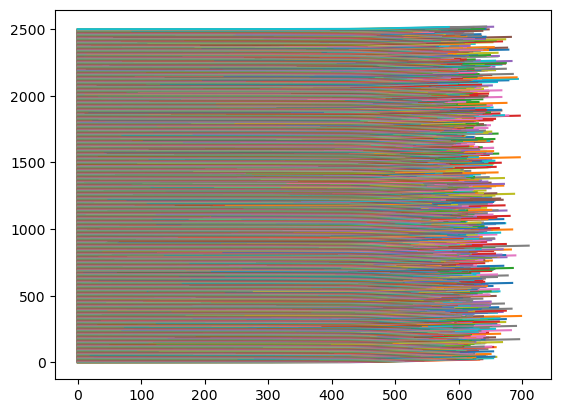

In [147]:
Fs = []

# Run this cell multiple times to generate more data

ru0_GT = 0.05
xu_GT = 0.2

for _ in tqdm(range(2500)):
    F = sim(C, ru0_GT, xu_GT)
    Fs.append(F)
for i, f in enumerate(Fs):
    plt.plot(f+i)
print(len(Fs), "Measurements")

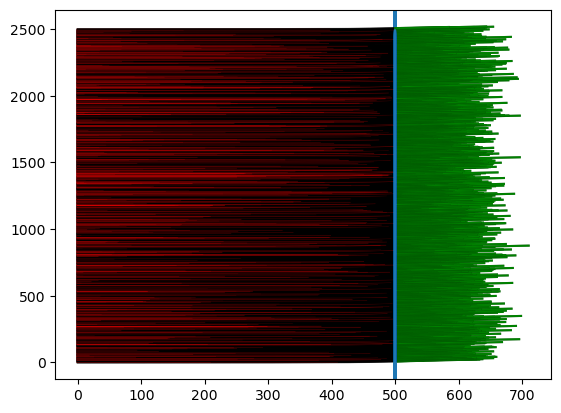

In [148]:
for i, f in enumerate(Fs):
    plt.axvline(cutoff)
    col = 'k' if len(f) > cutoff else 'r'
    plt.plot(f+i, color=col, alpha=0.5)
    fin = f[cutoff:]
    idx = np.arange(len(fin)) + cutoff
    plt.plot(idx, f[cutoff:]+i, color='g')

In [115]:
use = 1

In [149]:
def likelihood(Fs, xu, ru0, dt=1e-2):

    global pbar

    ''' Unnormalized logarithmic likelihood of the force curve
        under parameter xu and ru0. This does not include the
        time step, which scales the likelihood exponentially. '''

    logp = 0
    

    for F in Fs:
        N = len(F)
    
        F_stay_bound  = F[:-1]
        F_unbind      = F[-1]

        with np.errstate(divide='ignore'):
            logp_stay_bound  = np.log(1 - np.clip(dt * ru0 * np.exp(F_stay_bound * xu), 0, 1))
            logp_unbind = np.log(dt * ru0 * np.exp(F_unbind * xu))
            logp += np.sum(logp_unbind) + np.sum(logp_stay_bound)

    pbar.update(1)
    return logp



resolution = 200
cutoff  = 500


#F_run = Fs[:use]
#F_run = Fs
F_run = [f[cutoff:] for f in Fs if len(f) > cutoff]
print("Using", len(F_run))

with tqdm(total=resolution**2) as pbar:
    vecfun = np.vectorize(lambda xu, ru0: likelihood(F_run, xu, ru0))
    xu_max = xu_GT * 2.2
    ru0_max = ru0_GT * 2.2
    xu = np.linspace(0, xu_max, resolution)
    ru0 = np.linspace(0, ru0_max, resolution)
    RU0, XU = np.meshgrid(ru0, xu)
    LOGP = vecfun(XU, RU0)

LOGP -= LOGP.max()
P = np.exp(LOGP)
P_flat = np.sort(P.flatten())
CDF = np.cumsum(P_flat)
CDF = CDF / CDF[-1]
perc = 95
idx = np.argmax(CDF > (100 - perc)/100)

plt.plot([ru0_GT],[xu_GT], 'rx', markersize=10, markeredgewidth=2)

plt.imshow(P, origin='lower', extent=(0, ru0_max, 0, xu_max), aspect='auto', cmap='ocean_r')
plt.contour(P, origin='lower', extent=(0, ru0_max, 0, xu_max), levels=[P_flat[idx]], linestyles = '--', colors='k', alpha=0.8)
plt.title(f"Posteriors, {len(F_run)} trajectories, Dashed: {perc}th percentile")
plt.xlabel("ru0")
plt.ylabel("xu")
PRU0 = np.sum(P, axis=0)
PRU0 /= np.sum(PRU0)
plt.plot(ru0, PRU0, 'teal')
plt.fill_between(ru0, PRU0, color='teal')
PXU = np.sum(P, axis=1)
PXU /= np.sum(PXU)
plt.axvline(np.sum(ru0 * PRU0), color='g', linestyle='-', alpha=0.4)
plt.plot(PXU*0.1, xu, 'teal')
plt.fill_betweenx(xu, PXU*0.1, color='teal')
plt.axhline(np.sum(xu * PXU), color='g', linestyle='-', alpha=0.4)
plt.savefig(f"img/seq{use}.png", dpi=300)
plt.close()
use += 1

Using 1758


40001it [20:30, 32.51it/s]                                                      
